In [4]:
import pandas as pd
import json

from pathlib import Path

DATA_DIR = Path("../../data")
META_ROOT = DATA_DIR / "metadata.jsonl"
META_VIDEOS = DATA_DIR / "videos" / "metadata.jsonl"

In [5]:
def peek_jsonl(path, n=2):
    print(f"=== {path} ===")
    if not path.exists():
        print("  NOT FOUND")
        return
    with open(path, "r", encoding="utf-8") as f:
        for i, line in enumerate(f):
            if i >= n:
                break
            rec = json.loads(line)
            print(f"--- record {i} ---")
            for k, v in rec.items():
                s = str(v)
                print(f"  {k}: {s[:120]}{'...' if len(s) > 120 else ''}")
            print()

peek_jsonl(META_ROOT)
peek_jsonl(META_VIDEOS)

=== ../../data/metadata.jsonl ===
--- record 0 ---
  id: 0001
  file_name: videos/vid_0001.mp4
  duration: long
  question_id: 1
  question: Introduce yourself
  video_quality: High
  user_no: 147
  openness: -0.6530864781430419
  conscientiousness: -0.048687523913822875
  extraversion: -0.6910341478792781
  agreeableness: -0.29282249998209187
  neuroticism: 0.18964227851407364
  overall_personality: -0.028877340581066883
  interview_score: -0.92274277989017
  answer_score: -0.802644548060768
  speaking_skills: -0.7690474351952603
  confidence_score: -0.36181698330407713
  facial_expression: -0.8165911595299759
  overall_performance: -0.4563523865757841
  transcript: [00:01 - 00:11] Hello everyone, this is Mathurima Roy. I am a third year BTech student from Manipal University, Jaipur, ...
  gemini_summary: 1. Overview:
The candidate provides a clear, structured, and concise self-introduction. She effectively covers her acade...

--- record 1 ---
  id: 0002
  file_name: videos/vid_0002.

In [6]:
def load_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        return pd.DataFrame([json.loads(line) for line in f])

df_root = load_jsonl(META_ROOT)
df_videos = load_jsonl(META_VIDEOS)

print(f"root:   {df_root.shape}")
print(f"videos: {df_videos.shape}")
print(f"columns equal: {list(df_root.columns) == list(df_videos.columns)}")
print(f"data equal:    {df_root.equals(df_videos)}")

root:   (2011, 21)
videos: (2011, 21)
columns equal: True
data equal:    True


In [8]:
print("=== dtypes ===")
print(df_root.dtypes)
print("\n=== nulls ===")
print(df_root.isnull().sum())
print("\n=== unique counts ===")
for col in ["duration", "video_quality", "question_id", "user_no"]:
    print(f"{col}: {df_root[col].nunique()} unique")

=== dtypes ===
id                      object
file_name               object
duration                object
question_id             object
question                object
video_quality           object
user_no                 object
openness               float64
conscientiousness      float64
extraversion           float64
agreeableness          float64
neuroticism            float64
overall_personality    float64
interview_score        float64
answer_score           float64
speaking_skills        float64
confidence_score       float64
facial_expression      float64
overall_performance    float64
transcript              object
gemini_summary          object
dtype: object

=== nulls ===
id                     0
file_name              0
duration               0
question_id            0
question               0
video_quality          0
user_no                0
openness               0
conscientiousness      0
extraversion           0
agreeableness          0
neuroticism            0
overa

In [10]:
DATA_DIR_RESOLVED = (DATA_DIR).resolve()

video_paths = df_root["file_name"].apply(lambda p: DATA_DIR_RESOLVED / p)
exists = video_paths.apply(lambda p: p.exists())
print(f"video files referenced: {len(video_paths)}")
print(f"exist:                  {exists.sum()}")
print(f"missing:                {(~exists).sum()}")
if (~exists).any():
    print("\nmissing examples:")
    print(df_root.loc[~exists, "file_name"].head(10).tolist())

TARGETS = [
"openness", "conscientiousness", "extraversion", "agreeableness",
"neuroticism", "overall_personality",
"interview_score", "answer_score", "speaking_skills",
"confidence_score", "facial_expression", "overall_performance",
]

print(df_root[TARGETS].describe().T)
print("\n=== skew / kurtosis ===")
summary = pd.DataFrame({
    "skew": df_root[TARGETS].skew(),
    "kurtosis": df_root[TARGETS].kurtosis(),
})
print(summary)

video files referenced: 2011
exist:                  2011
missing:                0
                      count          mean       std        min       25%  \
openness             2011.0 -5.858129e-10  1.126621  -7.799628 -0.549269   
conscientiousness    2011.0 -1.810283e-09  0.876960  -6.928705 -0.448363   
extraversion         2011.0 -8.733420e-10  1.098106  -7.184409 -0.546418   
agreeableness        2011.0 -2.707772e-09  1.200348  -8.412302 -0.565689   
neuroticism          2011.0  5.822762e-10  0.486892  -2.576639 -0.306253   
overall_personality  2011.0 -4.385845e-09  1.203363  -7.526180 -0.611467   
interview_score      2011.0  7.469935e-12  1.230107  -7.860317 -0.595702   
answer_score         2011.0  1.960056e-10  1.175536 -10.199055 -0.610569   
speaking_skills      2011.0  2.853436e-10  1.277570  -9.406297 -0.558023   
confidence_score     2011.0  2.639436e-10  1.079704  -7.286060 -0.535231   
facial_expression    2011.0  2.253832e-10  1.151031  -7.461446 -0.583835   
over

In [11]:
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

df_root[TARGETS].describe().T.to_csv(RESULTS_DIR / "targets_describe.csv")
summary.to_csv(RESULTS_DIR / "targets_skew_kurtosis.csv")
print("saved to", RESULTS_DIR.resolve())

saved to /home/snomty/hse-2027-final-qualifying-work/experiments/001_eda_dataset_structure/results


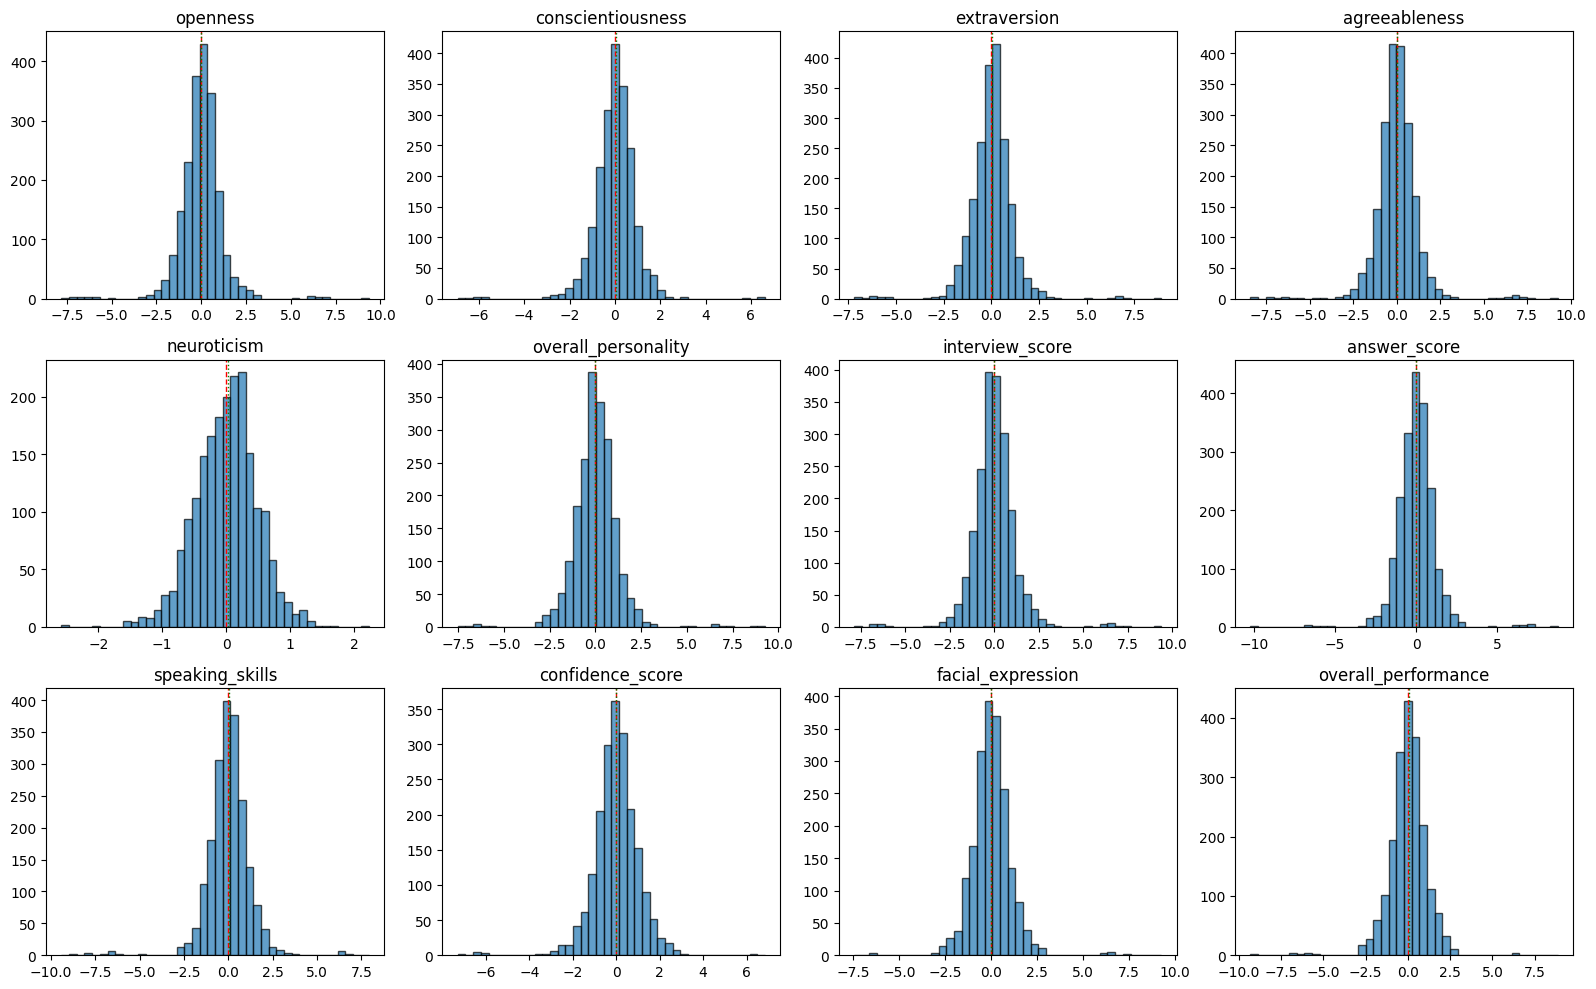

In [12]:
import matplotlib.pyplot as plt

TARGETS = [
    "openness", "conscientiousness", "extraversion", "agreeableness",
    "neuroticism", "overall_personality",
    "interview_score", "answer_score", "speaking_skills",
    "confidence_score", "facial_expression", "overall_performance",
]

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, TARGETS):
    ax.hist(df_root[col], bins=40, edgecolor="black", alpha=0.7)
    ax.set_title(col)
    ax.axvline(df_root[col].mean(), color="red", linestyle="--", linewidth=1)
    ax.axvline(df_root[col].median(), color="green", linestyle=":", linewidth=1)
plt.tight_layout()
plt.savefig("results/targets_histograms.png", dpi=150)
plt.show()

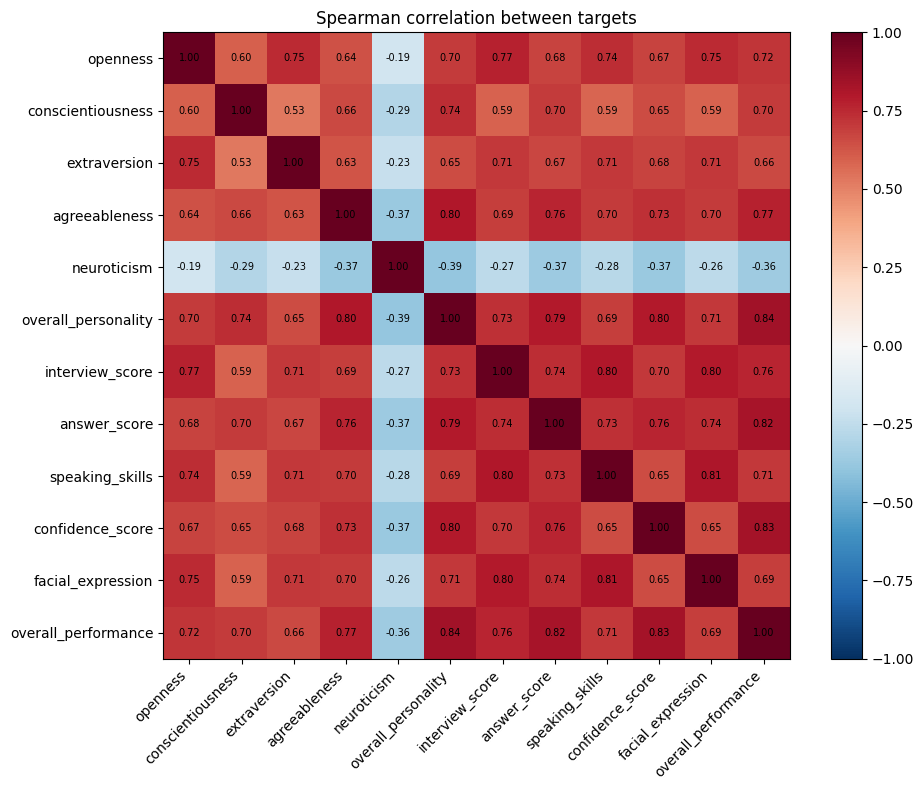

In [13]:
import numpy as np

corr = df_root[TARGETS].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(TARGETS)))
ax.set_yticks(range(len(TARGETS)))
ax.set_xticklabels(TARGETS, rotation=45, ha="right")
ax.set_yticklabels(TARGETS)
for i in range(len(TARGETS)):
    for j in range(len(TARGETS)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, ax=ax)
plt.title("Spearman correlation between targets")
plt.tight_layout()
plt.savefig("results/targets_correlation.png", dpi=150)
plt.show()

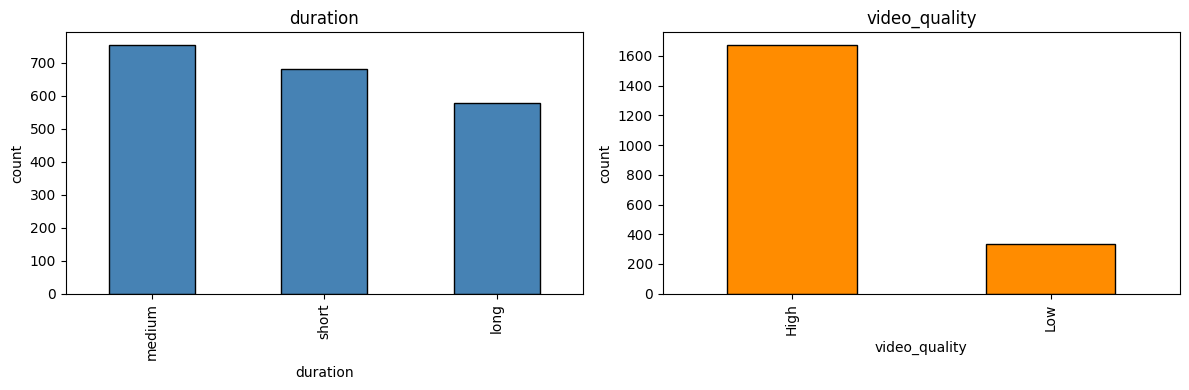

duration
medium    0.375
short     0.338
long      0.287
Name: proportion, dtype: float64

video_quality
High    0.833
Low     0.167
Name: proportion, dtype: float64


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df_root["duration"].value_counts().plot(kind="bar", ax=axes[0], color="steelblue", edgecolor="black")
axes[0].set_title("duration")
axes[0].set_ylabel("count")

df_root["video_quality"].value_counts().plot(kind="bar", ax=axes[1], color="darkorange", edgecolor="black")
axes[1].set_title("video_quality")
axes[1].set_ylabel("count")

plt.tight_layout()
plt.savefig("results/categorical_counts.png", dpi=150)
plt.show()

print(df_root["duration"].value_counts(normalize=True).round(3))
print()
print(df_root["video_quality"].value_counts(normalize=True).round(3))

unique questions: 76
min samples per question: 14 (question 65)
max samples per question: 193 (question 1)
median: 21.0



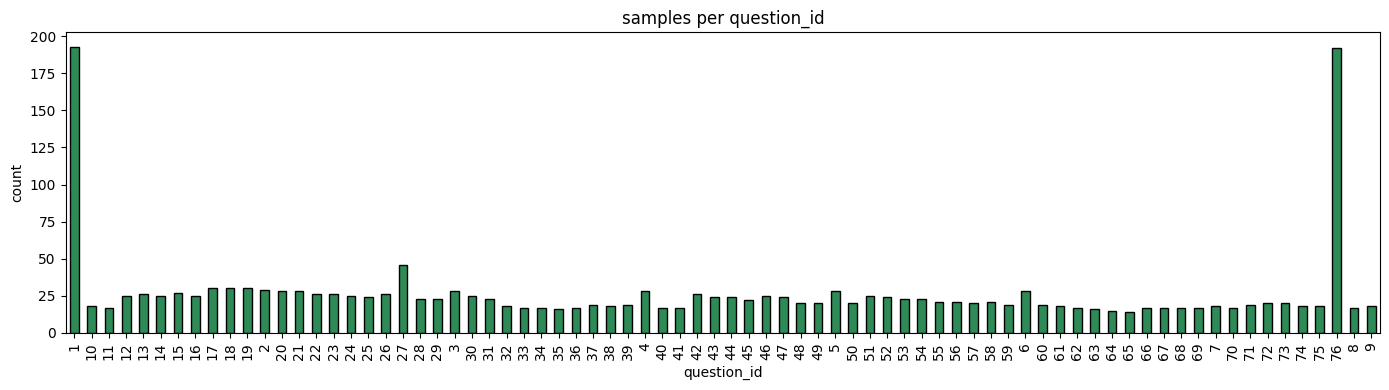

In [18]:
q_counts = df_root["question_id"].value_counts().sort_index()
print(f"unique questions: {q_counts.shape[0]}")
print(f"min samples per question: {q_counts.min()} (question {q_counts.idxmin()})")
print(f"max samples per question: {q_counts.max()} (question {q_counts.idxmax()})")
print(f"median: {q_counts.median():.1f}")
print()

fig, ax = plt.subplots(figsize=(14, 4))
q_counts.plot(kind="bar", ax=ax, color="seagreen", edgecolor="black")
ax.set_title("samples per question_id")
ax.set_xlabel("question_id")
ax.set_ylabel("count")
plt.tight_layout()
plt.savefig("results/questions_distribution.png", dpi=150)
plt.show()

unique users: 331
min videos per user: 1
max videos per user: 17
median: 6.0
mean: 6.08



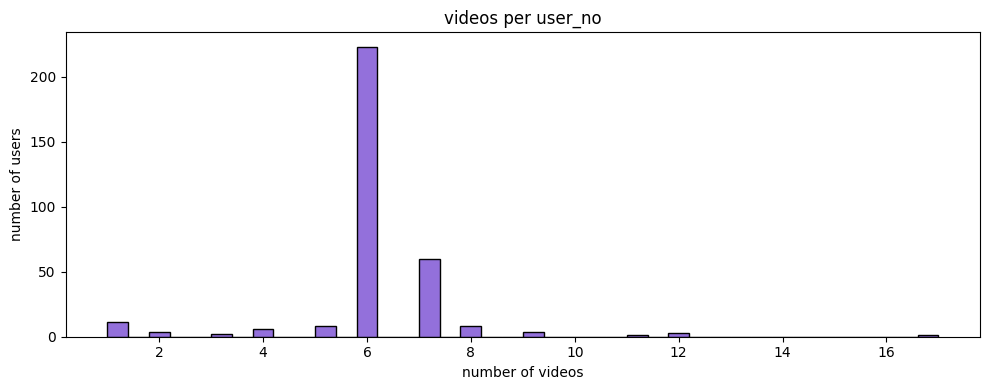

In [19]:
u_counts = df_root["user_no"].value_counts()
print(f"unique users: {u_counts.shape[0]}")
print(f"min videos per user: {u_counts.min()}")
print(f"max videos per user: {u_counts.max()}")
print(f"median: {u_counts.median():.1f}")
print(f"mean: {u_counts.mean():.2f}")
print()

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(u_counts, bins=40, edgecolor="black", color="mediumpurple")
ax.set_title("videos per user_no")
ax.set_xlabel("number of videos")
ax.set_ylabel("number of users")
plt.tight_layout()
plt.savefig("results/users_distribution.png", dpi=150)
plt.show()

=== transcript lengths (words) ===
count    2011.0
mean       81.9
std        51.1
min         0.0
25%        41.0
50%        72.0
75%       115.0
max       256.0
Name: transcript_len_words, dtype: float64

=== gemini_summary lengths (words) ===
count    2011.0
mean      881.2
std        85.3
min       106.0
25%       833.5
50%       884.0
75%       931.0
max      1139.0
Name: summary_len_words, dtype: float64

empty transcripts: 13
empty summaries:   0


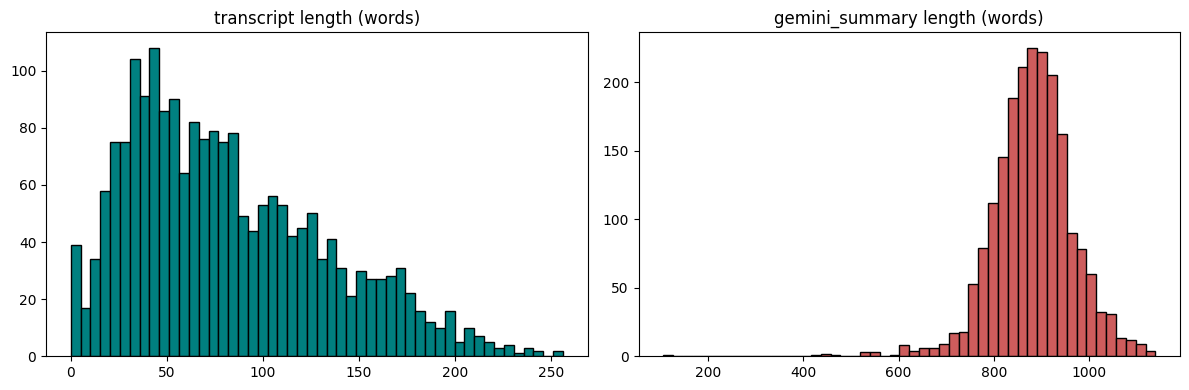

In [20]:
df_root["transcript_len_chars"] = df_root["transcript"].str.len()
df_root["transcript_len_words"] = df_root["transcript"].str.split().str.len()
df_root["summary_len_chars"]  = df_root["gemini_summary"].str.len()
df_root["summary_len_words"]  = df_root["gemini_summary"].str.split().str.len()

print("=== transcript lengths (words) ===")
print(df_root["transcript_len_words"].describe().round(1))
print("\n=== gemini_summary lengths (words) ===")
print(df_root["summary_len_words"].describe().round(1))

print(f"\nempty transcripts: {(df_root['transcript_len_words'] == 0).sum()}")
print(f"empty summaries:   {(df_root['summary_len_words'] == 0).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df_root["transcript_len_words"], bins=50, edgecolor="black", color="teal")
axes[0].set_title("transcript length (words)")
axes[1].hist(df_root["summary_len_words"], bins=50, edgecolor="black", color="indianred")
axes[1].set_title("gemini_summary length (words)")
plt.tight_layout()
plt.savefig("results/text_lengths.png", dpi=150)
plt.show()